## Градиентный спуск

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing()
X = pd.DataFrame(data.data, columns=data.feature_names)
Y = pd.Series(data.target, name="target")

In [ ]:
X.shape

(20640, 8)

Пусть у нас есть 20640 объектов и 8 признаков у каждого (+таргет)

Обучим модель линейной регрессии:

$$
a(x) = \beta_1 d_{1} + \beta_2 d_{2} + \beta_3 d_{3} + \beta_4 d_{4} + \beta_5 d_{5} + \beta_6 d_{6} + \beta_7 d_{7} + \beta_8 d_{8}  + \beta_0
$$

Которая минимизирует MSE:

$$
Q(a(X), Y) = \sum_i^{20640} (a(x_i) - y_i)^2
$$

In [ ]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000


In [ ]:
Y

,target
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422
...,...
20635,0.781
20636,0.771
20637,0.923
20638,0.847


Обучим коэффициенты линейной регрессии с помощью библиотеки <a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html"> **sklearn** </a>

Отдельно выведем оценку свободного коэффициента  ($\beta_0$ при $d_0 = 1$)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns
)

Y_scaled = (Y - Y.mean()) / Y.std()

In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_scaled, Y_scaled)

LinearRegression()

In [ ]:
model.coef_

array([ 0.71893486,  0.10290829, -0.23010136,  0.26491148, -0.00390223,
       -0.03407952, -0.77982655, -0.75439695])

In [ ]:
model.intercept_

np.float64(-7.080686956390794e-15)

Теперь вам необходимо реализовать класс для оптимизации коэффициентов линейной регрессии МНК.
Подразумевается, что на вход алгоритм будет принимать следующие параметры:

- 2 pandas датафрейма **samples** и **targets**, содержащих матрицу объектов и ветор ответов соответственно
- значение **learning rate**, который корректирует длину вектора-градиента (чтобы он не взорвался)
- значение **threshold**'а для критерия останова (когда мы считаем, что мы сошлись к оптимуму)
- параметр **copy**, который позволяет либо делать изменения in-place в датафрейме, подающимся в класс, если изменения матрицы объектов в принципе при обучении имеются. Или же копировать объект при инициализации класса и возвращать новый объект, если требуется.

Он будет состоять из следующих важных компонент-методов:

- **add_constant**: добавляет колонку с названием *constant* из единичек к переданному датафрейму **samples**. Это позволяет оценить свободный коэффициент $\beta_0$.

- **calculate_mse**: вычисляет при текущих весах **self.beta** значение среднеквадратической ошибки.

- **calculate_grad**: вычисляет при текущих весах вектор-градиент по функционалу.

- **iteration**: производит итерацию градиентного спуска, то есть обновляет веса модели, в соответствии с установленным **learning_rate = $\eta$**: $\beta^{(n+1)} = \beta^{(n)} - \eta \cdot \nabla Q(\beta^{(n)})$

- **learn**: производит итерации обучения до того момента, пока не сработает критерий останова обучения. В этот раз критерием останова будет следующее событие: во время крайней итерации изменение в функционале качества модели составило значение меньшее, чем **self.threshold**. Иными словами, $|Q(\beta^{(n)}) - Q(\beta^{(n+1)})| < threshold$.

### Hint: пример вычисления производной

$$
Q(a, X) = \frac{1}{N}\cdot\sum_{i=1}^N (\beta_1 \cdot d_{i1} + ... + \beta_n \cdot d_{in} - y_i)^2
$$

Выше - минимизируемая функция. Она зависит от n переменных: $\beta_1, ..., \beta_n$. Вектор-градиент - матрица с одной строчкой, состоящей из производных 1го порядка по всем переменным.

$$
\nabla Q(a, X) = (Q'_{\beta_1} \;\;\; Q'_{\beta_2} \;\;\; ... \;\;\; Q'_{\beta_{n-1}}  \;\;\;  Q'_{\beta_n})
$$

Пример вычисления производной по первой переменной:

$$
Q'_{\beta_1} = \frac{2}{N} \cdot \sum_{i=1}^N d_{i1} (\beta_1 \cdot d_{i1} + ... + \beta_{n} \cdot d_{in} - y_i)
$$

Скажем, для нашего датасета X, Y вычислим эту саму производную при начальных единичных коэффициентах $\beta_{start} = (1 \;\;\; 1 \;\;\; ...)$



Получим для каждого объекта в начале выражение из скобочек:
$$
\beta_1 \cdot d_{i1} + ... + \beta_{n} \cdot d_{in} - y_i
$$

In [ ]:

initial_betas = np.ones(X.shape[1])

scalar_value = np.dot(X, initial_betas.reshape(-1, 1)).ravel()
scalar_value = (scalar_value - Y).values

In [ ]:
scalar_value

array([ 293.01269206, 2351.6762594 ,  479.51024181, ...,  951.63827021,
        686.75484183, 1331.65856226])

Теперь полученное значение для каждого объекта умножим на соответствующее значение признака $d_1$:

$$
d_{i1} \cdot (\beta_1 \cdot d_{i1} + ... + \beta_{n} \cdot d_{in} - y_i)
$$

In [ ]:
d_i1 = X.values[:, 0]

### Умножим каждый объект на соответствующее значение признака
scalar_value = scalar_value * d_i1

In [ ]:
2 * np.mean(scalar_value)

np.float64(10717.507797161326)

### Эта логика поможем Вам при реализации!

In [ ]:
def calculate_mse(beta: np.ndarray, samples: np.ndarray, targets: np.ndarray) -> float:
    """
    Метод для расчета среднеквадратической ошибки.

    :return: среднеквадратическая ошибка при текущих весах модели : float
    """
    loss = np.mean((samples @ beta - targets)**2)
    return loss

def add_constant(samples: np.ndarray, beta: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Функция для создания константной фичи в матрице объектов samples.
    Добавляет колонку с единицами и обновляет вектор весов.
    """
    samples['constants'] = 1

    beta = np.append(beta, 1)

    return samples, beta


def calculate_grad(beta: np.ndarray, samples: np.ndarray, targets: np.ndarray) -> np.ndarray:
    """
    Функция для вычисления вектора-градиента.

    :return: вектор-градиент, содержащий производные по каждому признаку : np.ndarray
    """

    diff = samples @ beta - targets

    gradient =  2/samples.shape[0] * (samples.T @ diff)

    return gradient

def iteration(beta: np.ndarray, samples: np.ndarray, targets: np.ndarray, learning_rate: float) -> np.ndarray:
    """
    Обновляем веса модели в соответствии с текущим вектором-градиентом.
    """
    new_beta = beta - learning_rate * calculate_grad(beta, samples, targets)
    return new_beta

def learn(samples: pd.DataFrame, targets: pd.DataFrame,
                learning_rate: float = 1e-3, threshold: float=1e-6, max_iter: int = 100000) -> tuple[np.ndarray, int, dict]:
    """
    Итеративное обучение весов модели до срабатывания критерия останова.

    Запись mse и номера итерации в iteration_loss_dict.
    """

    samples = samples.copy()
    targets = targets.copy()

    beta = np.ones(samples.shape[1])
    samples, beta = add_constant(samples, beta)
    samples = np.array(samples)

    targets = targets.values.reshape(-1)

    beta = np.ones(samples.shape[1])
    iteration_loss_dict = {0 : calculate_mse(beta, samples, targets)}

    for itera in range(1, max_iter+1):
        start_betas = beta.copy()
        new_beta = iteration(start_betas, samples, targets, learning_rate)

        new_mse = calculate_mse(new_beta, samples, targets)

        iteration_loss_dict[itera] = new_mse

        if abs(new_mse - iteration_loss_dict[itera-1]) < threshold:
            beta = new_beta
            break


        beta = new_beta
        print(new_mse, "                 ", end="\r")

    if itera == max_iter:
        print("Алгоритм расходится(")

    return beta, itera, iteration_loss_dict

In [ ]:
beta_, itera_, iteration_loss_dict_ = learn(X_scaled, Y_scaled, learning_rate=0.1, threshold=1e-10, max_iter=500000)

In [ ]:
print('Веса модели при переменных d1, d2, ..., d10 равны соответственно: \n\n' + str(beta_))

Веса модели при переменных d1, d2, ..., d10 равны соответственно: 

[ 7.19018138e-01  1.02923750e-01 -2.30258990e-01  2.65041949e-01
 -3.89768479e-03 -3.40825995e-02 -7.79635625e-01 -7.54215724e-01
 -7.05342512e-15]


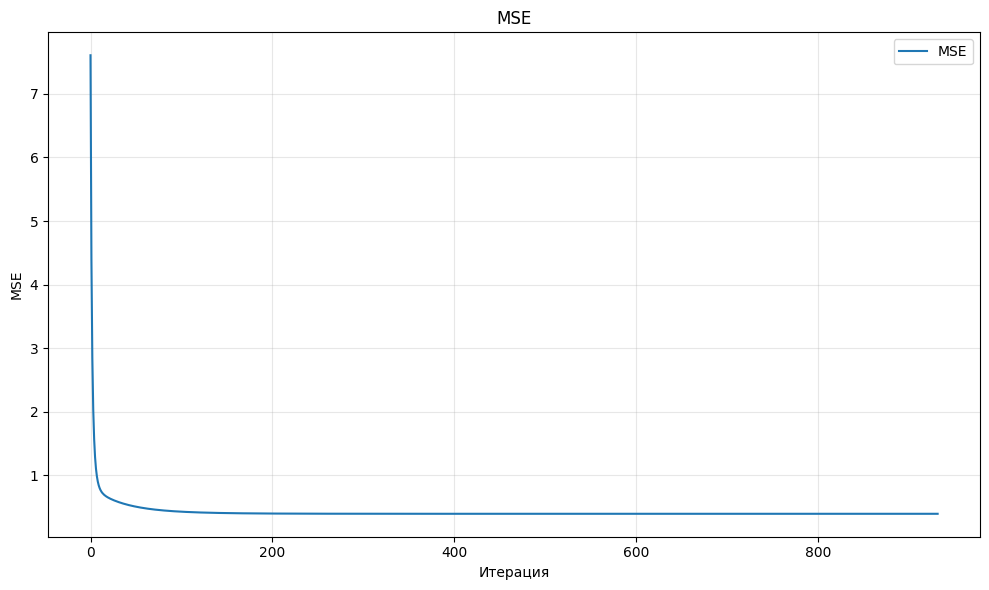

In [ ]:
import matplotlib.pyplot as plt

def plot_loss(iteration_loss_dict, title="MSE"):
    iters = sorted(iteration_loss_dict.keys())
    losses = [iteration_loss_dict[i] for i in iters]

    plt.figure(figsize=(10, 6))
    plt.plot(iters, losses, linewidth=1.5, label="MSE")


    plt.xlabel("Итерация")
    plt.ylabel("MSE")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_loss(iteration_loss_dict_)